# Filtros lineares e não-lineares

Implementação manual dos filtros vistos em aula, **sem usar funções do OpenCV** (nem `cv2.filter2D`, `cv2.blur`, `cv2.medianBlur` etc.):

| Filtro | Tipo | Como é calculado em cada vizinhança |
|---|---|---|
| Média | linear | convolução com um kernel de pesos iguais `1/(k·k)` |
| Mediana | não-linear | valor central dos pixels ordenados |
| Moda | não-linear | valor de intensidade que mais se repete |
| Máxima | não-linear | maior valor da vizinhança |

A convolução é feita à mão (função `convolucao`) e os filtros não-lineares usam uma função de janela deslizante (`aplicar_janela`), que percorre a imagem do mesmo jeito que a convolução, mas aplica uma operação de ordenação/contagem em vez da soma ponderada.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

plt.rcParams['figure.dpi'] = 80

## Imagem de exemplo

Uso a imagem `camera` do `skimage.data`, que já vem em escala de cinza (`uint8`, 512×512).

formato: (512, 512) | tipo: uint8 | min/max: 0 255


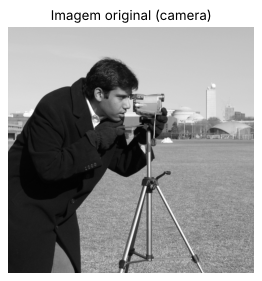

In [2]:
img = data.camera()
print('formato:', img.shape, '| tipo:', img.dtype, '| min/max:', img.min(), img.max())

plt.figure(figsize=(4, 4))
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Imagem original (camera)')
plt.axis('off')
plt.show()

## Funções base

### Padding
Para que a imagem filtrada tenha o mesmo tamanho da original, a borda é estendida com `k//2` pixels de cada lado. Uso o modo `edge` (replica o pixel da borda), que evita a moldura escura que o preenchimento com zeros criaria.

### Convolução manual
Para cada pixel `(i, j)`, recorto a janela `k×k` centrada nele, multiplico elemento a elemento pelo kernel **rotacionado 180°** (é isso que diferencia convolução de correlação) e somo.

In [3]:
def aplicar_padding(img, pad):
    """Estende a borda da imagem replicando os pixels das extremidades."""
    return np.pad(img, pad_width=pad, mode='edge')


def convolucao(img, kernel):
    """Convolução 2D manual (sem OpenCV).

    img    : imagem em tons de cinza (2D)
    kernel : matriz k x k (k ímpar)
    Retorna uma imagem float do mesmo tamanho da entrada.
    """
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    assert kh % 2 == 1 and kw % 2 == 1, 'o kernel precisa ter dimensões ímpares'

    kernel_rot = kernel[::-1, ::-1]          # rotação de 180°
    ph, pw = kh // 2, kw // 2
    img_pad = aplicar_padding(img.astype(np.float64), ((ph, ph), (pw, pw)))

    altura, largura = img.shape
    saida = np.zeros((altura, largura), dtype=np.float64)

    for i in range(altura):
        for j in range(largura):
            janela = img_pad[i:i + kh, j:j + kw]
            saida[i, j] = np.sum(janela * kernel_rot)
    return saida


def aplicar_janela(img, k, operacao):
    """Percorre a imagem com uma janela k x k e aplica `operacao` em cada vizinhança.
    Base dos filtros não-lineares (mediana, moda, máxima)."""
    assert k % 2 == 1, 'k precisa ser ímpar'
    p = k // 2
    img_pad = aplicar_padding(img, p)

    altura, largura = img.shape
    saida = np.zeros((altura, largura), dtype=img.dtype)

    for i in range(altura):
        for j in range(largura):
            janela = img_pad[i:i + k, j:j + k]
            saida[i, j] = operacao(janela)
    return saida

### Teste rápido da convolução
Antes de usar na imagem, confiro a convolução numa matriz pequena, feita à mão. Com o kernel de média 3×3, o pixel central de uma matriz 3×3 com valores 1..9 deve virar a média deles, que é 5.

In [4]:
teste = np.arange(1, 10).reshape(3, 3)
kernel_media_3 = np.ones((3, 3)) / 9
print(teste)
print('valor central após convolução:', convolucao(teste, kernel_media_3)[1, 1])

# Kernel assimétrico: confirma que o kernel é rotacionado (convolução, não correlação).
# Um impulso convoluído com o kernel deve reproduzir o próprio kernel.
impulso = np.zeros((5, 5)); impulso[2, 2] = 1
k_assim = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
print('impulso * kernel (região central):')
print(convolucao(impulso, k_assim)[1:4, 1:4])

[[1 2 3]
 [4 5 6]
 [7 8 9]]
valor central após convolução: 5.0
impulso * kernel (região central):
[[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]


## Os quatro filtros

Cada filtro é uma função própria. Todos recebem a imagem e o tamanho da janela `k` e devolvem uma imagem `uint8`.

In [5]:
def filtro_media(img, k=3):
    """Filtro linear: convolução com kernel de pesos iguais 1/(k*k)."""
    kernel = np.ones((k, k), dtype=np.float64) / (k * k)
    saida = convolucao(img, kernel)
    return np.clip(np.round(saida), 0, 255).astype(np.uint8)


def filtro_mediana(img, k=3):
    """Filtro não-linear: ordena os k*k valores e pega o do meio."""
    meio = (k * k) // 2
    def mediana(janela):
        return np.sort(janela, axis=None)[meio]
    return aplicar_janela(img, k, mediana)


def filtro_moda(img, k=3):
    """Filtro não-linear: valor de intensidade mais frequente na janela.
    Em caso de empate, fica o menor valor (comportamento do argmax)."""
    def moda(janela):
        contagem = np.bincount(janela.ravel(), minlength=256)
        return np.argmax(contagem)
    return aplicar_janela(img, k, moda)


def filtro_maxima(img, k=3):
    """Filtro não-linear: maior valor da janela."""
    def maximo(janela):
        return janela.max()
    return aplicar_janela(img, k, maximo)

Todos com janela `k = 5`, para o efeito ficar visível na imagem 512×512 (com 3×3 a diferença é sutil demais no tamanho da figura).

In [6]:
import time

K = 5
resultados = {}
for nome, funcao in [('Média', filtro_media), ('Mediana', filtro_mediana),
                     ('Moda', filtro_moda), ('Máxima', filtro_maxima)]:
    t0 = time.time()
    resultados[nome] = funcao(img, K)
    print(f'{nome:8s} -> {time.time() - t0:.1f} s')

Média    -> 0.6 s


Mediana  -> 0.4 s


Moda     -> 0.6 s


Máxima   -> 0.3 s


In [7]:
def comparar(original, filtrada, titulo, zoom=None):
    """Subplot lado a lado: original x filtrada (e, opcionalmente, um recorte ampliado)."""
    colunas = 4 if zoom else 2
    fig, ax = plt.subplots(1, colunas, figsize=(4 * colunas, 4.2))
    ax[0].imshow(original, cmap='gray', vmin=0, vmax=255); ax[0].set_title('Original')
    ax[1].imshow(filtrada, cmap='gray', vmin=0, vmax=255); ax[1].set_title(titulo)
    if zoom:
        (r0, r1), (c0, c1) = zoom
        ax[2].imshow(original[r0:r1, c0:c1], cmap='gray', vmin=0, vmax=255); ax[2].set_title('Original (zoom)')
        ax[3].imshow(filtrada[r0:r1, c0:c1], cmap='gray', vmin=0, vmax=255); ax[3].set_title(titulo + ' (zoom)')
    for a in ax:
        a.axis('off')
    plt.tight_layout()
    plt.show()

# recorte do rosto/câmera do fotógrafo, onde os detalhes finos aparecem melhor
ZOOM = ((80, 230), (180, 330))

### Filtro da média (linear)
Cada pixel vira a média dos 25 vizinhos. O resultado é um borramento uniforme: ruído e textura do gramado são suavizados, mas as bordas (contorno do casaco, tripé) também perdem nitidez, porque o filtro não distingue borda de ruído.

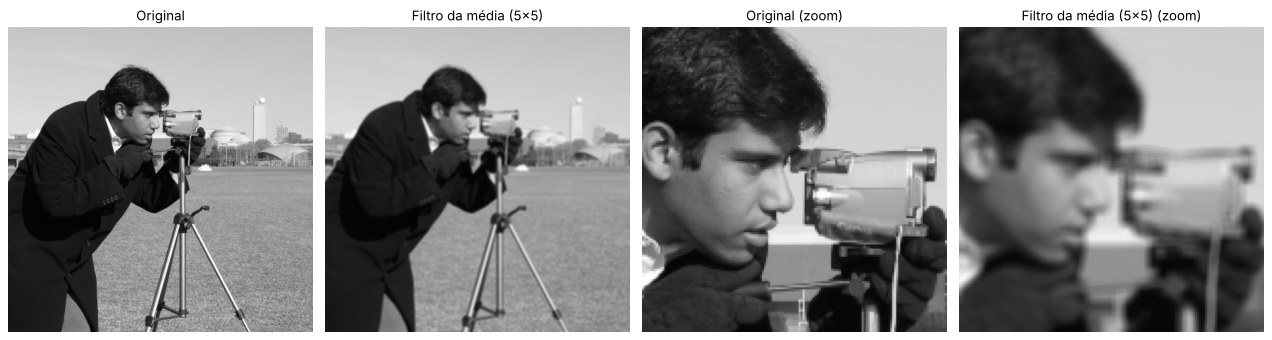

In [8]:
comparar(img, resultados['Média'], 'Filtro da média ({K}x{K})'.format(K=K), zoom=ZOOM)

### Filtro da mediana (não-linear)
Também suaviza, mas preserva bem melhor as bordas: como o valor escolhido é sempre um pixel que existe na vizinhança, não aparecem os tons intermediários "inventados" que a média cria nas transições. Detalhes muito finos (mais estreitos que meia janela, como as hastes do tripé) tendem a ser apagados.

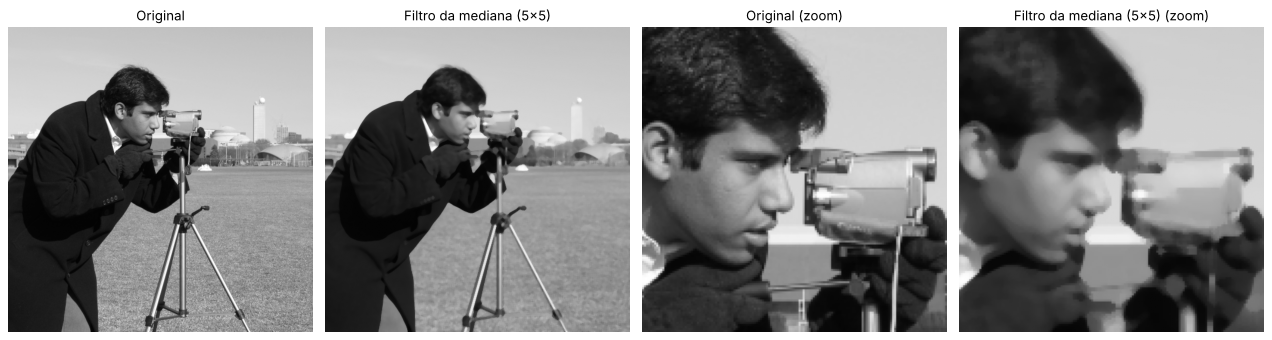

In [9]:
comparar(img, resultados['Mediana'], 'Filtro da mediana ({K}x{K})'.format(K=K), zoom=ZOOM)

### Filtro da moda (não-linear)
Escolhe o tom mais frequente da vizinhança. Isso "achata" regiões em blocos de tom constante, com aspecto de posterização, e mantém as bordas duras. Em áreas com muitas tonalidades diferentes (onde quase nenhum valor se repete), o empate é resolvido pelo menor valor, o que puxa levemente a imagem para tons mais escuros.

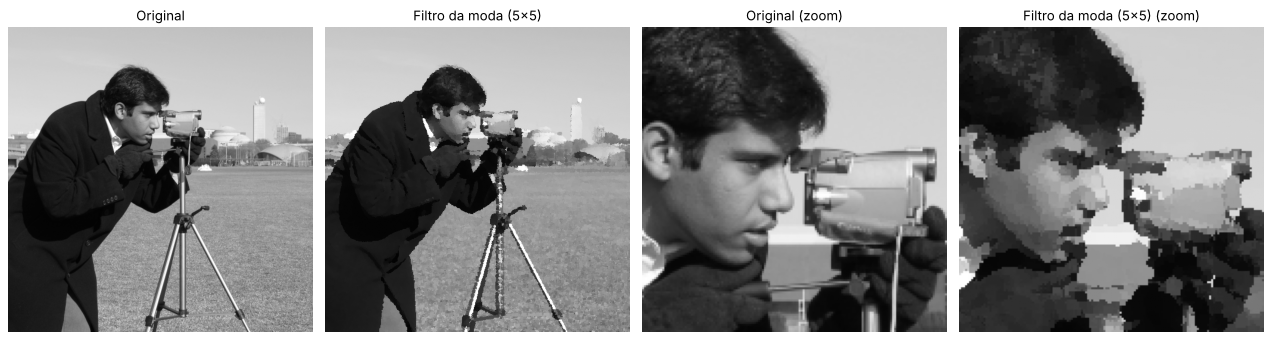

In [10]:
comparar(img, resultados['Moda'], 'Filtro da moda ({K}x{K})'.format(K=K), zoom=ZOOM)

### Filtro da máxima (não-linear)
Cada pixel vira o mais claro da vizinhança. Regiões claras se expandem e as escuras encolhem (equivale à dilatação em tons de cinza): o casaco preto do fotógrafo afina, o tripé quase some e a imagem fica mais clara no geral. É útil para remover ruído do tipo "pimenta" (pontos pretos).

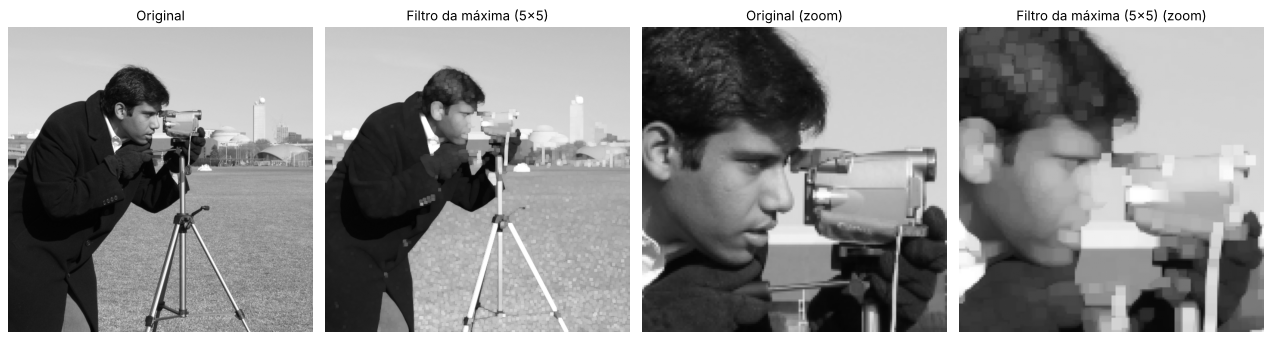

In [11]:
comparar(img, resultados['Máxima'], 'Filtro da máxima ({K}x{K})'.format(K=K), zoom=ZOOM)

## Visão geral

Os quatro resultados juntos, para comparar os efeitos.

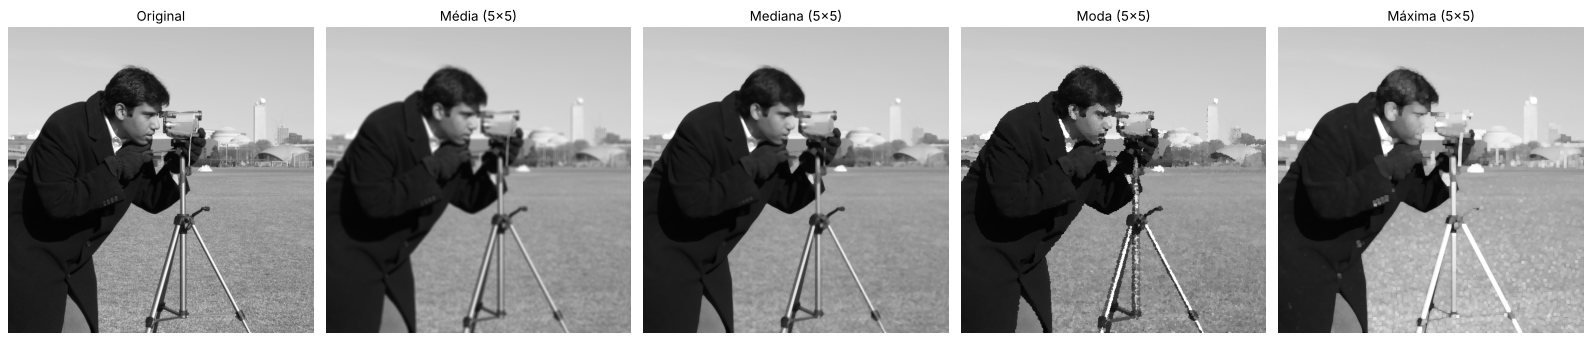

In [12]:
fig, ax = plt.subplots(1, 5, figsize=(20, 4.4))
ax[0].imshow(img, cmap='gray', vmin=0, vmax=255); ax[0].set_title('Original')
for a, (nome, res) in zip(ax[1:], resultados.items()):
    a.imshow(res, cmap='gray', vmin=0, vmax=255)
    a.set_title(f'{nome} ({K}x{K})')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

## Extra: imagem com ruído sal e pimenta

Para mostrar a diferença prática entre filtro linear e não-linear, adiciono ruído impulsivo (5% dos pixels viram 0 ou 255) e aplico média e mediana 3×3. A média só espalha os pontos em manchas cinzas; a mediana os elimina quase por completo, porque um valor extremo isolado nunca fica no meio da lista ordenada.

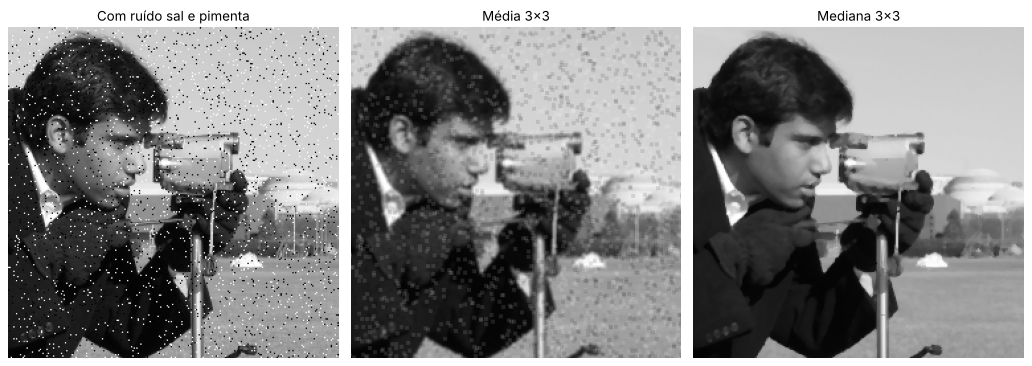

In [13]:
rng = np.random.default_rng(42)
ruidosa = img.copy()
mascara = rng.random(img.shape)
ruidosa[mascara < 0.025] = 0
ruidosa[mascara > 0.975] = 255

media_ruido = filtro_media(ruidosa, 3)
mediana_ruido = filtro_mediana(ruidosa, 3)

fig, ax = plt.subplots(1, 3, figsize=(13, 4.6))
for a, im, t in zip(ax, [ruidosa, media_ruido, mediana_ruido],
                    ['Com ruído sal e pimenta', 'Média 3x3', 'Mediana 3x3']):
    a.imshow(im[60:310, 150:400], cmap='gray', vmin=0, vmax=255)
    a.set_title(t); a.axis('off')
plt.tight_layout()
plt.show()

## Conclusão

- **Média** é o único filtro linear dos quatro e o único que precisa de convolução: suaviza tudo por igual, inclusive as bordas.
- **Mediana** suaviza preservando bordas e é a melhor escolha contra ruído impulsivo (sal e pimenta).
- **Moda** produz regiões de tom constante (efeito de posterização) e é pouco usada em fotos naturais, mas faz sentido em imagens com poucos níveis, como mapas de rótulos.
- **Máxima** expande as regiões claras (dilatação); a sua contraparte, o filtro da mínima, faria o oposto.